In [1]:
import astropy.units as u
import numpy as np
import pandas as pd

import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/')

from ic_processing import read_map, get_moc_map_metadata
from ic_visualization import plot_full_map, plot_zoomed_IC_alert

from Neutrino import Neutrino
from Transient import Transient

from Signal import spatial_signal_pdf, temporal_signal_pdf, emission_signal_pdf
from Background import spatial_bkg_pdf, temporal_bkg_pdf, emission_bkg_pdf

/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


First we get a neutrino

In [2]:
from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)



Map has masked values. reeplacing them with 0


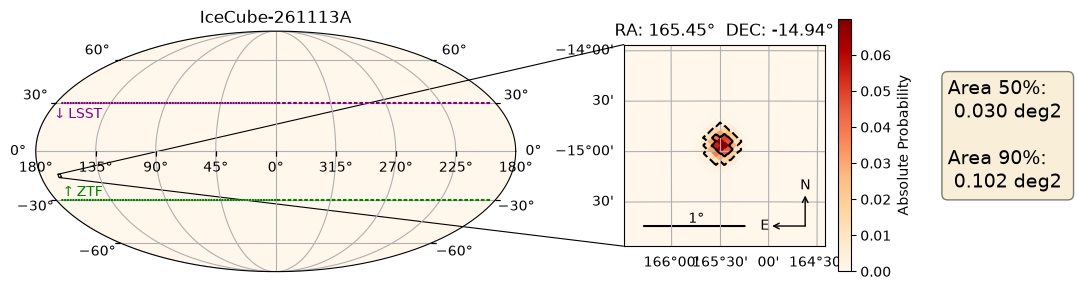

In [3]:
alert = alerts[-1]
neutrino = read_map(alert['healpix_url'])
_ = plot_full_map(neutrino, save_dir='', r=1)

### 2. Get the neutrino

In [4]:
nu = Neutrino(neutrino, 1e5*u.GeV)

### 3. Generate 3 transients

* 1 transientat the neutrino best fit position
* 2 transients around the 90% region

First the source

In [5]:
transient = {
    'name': 'Source',
    'ra': 165.45,
    'dec': -14.94,
    'z': 1.0,
    't_peak': nu.t - 2*u.d,
    'p_k': {
        'SN Ib/c': 1.0,
    }
}
ts1 = Transient(transient)

Now 2 backrgound sources

In [6]:
transients_bkg = [{
    'name': 'Bkg 1',
    'ra': 165.45 -0.1,
    'dec': -14.94 - 0.1,
    'z': 1.2,
    't_peak': nu.t + 5*u.d,
    'p_k': {
        'SN Ib/c': 1.0,
    }
},
{
    'name': 'Bkg 2',
    'ra': 165.45 + 0.1,
    'dec': -14.94 + 0.1,
    'z': 0.8,
    't_peak': nu.t - 3*u.d,
    'p_k': {
        'SN Ib/c': 1.0,
    }
}]

all_transients = list()
all_transients.extend([transient])
all_transients.extend(transients_bkg)

In [7]:
tb1, tb2 = Transient(transients_bkg[0]), Transient(transients_bkg[1])

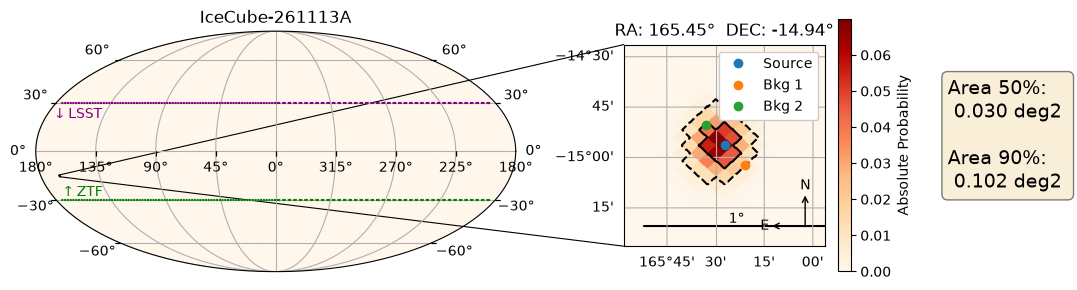

('IceCube-261113A.png',
 <Quantity 0.10163321 deg2>,
 <mhealpy.containers.healpix_map.HealpixMap at 0x12a887490>)

In [8]:
plot_full_map(neutrino, save_dir='', plot_source=all_transients, r=0.5)

### 4. Now we start testing the analysis

##### 4. 1Spatial Signal

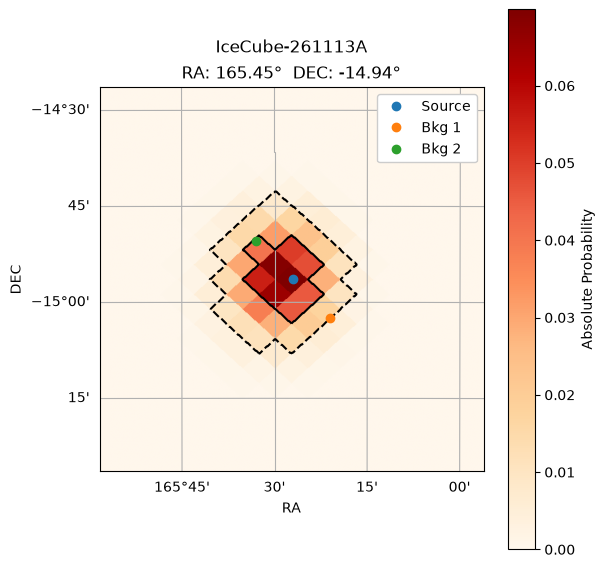

In [9]:
plot_zoomed_IC_alert(neutrino, save_dir='', plot_source=all_transients, r=0.5)

In [10]:
print('Transient | ra | dec | p_spatial')
for t in [ts1, tb1, tb2]:
    p_spatial = spatial_signal_pdf(nu, t)
    # print('p_spatial ', t.name, ' : ', p_spatial)
    print(t.name, ' | ', t.ra, ' | ', t.dec, ' | ', p_spatial)


Transient | ra | dec | p_spatial
Source  |  165.45 deg  |  -14.94 deg  |  0.06783949618652658
Bkg 1  |  165.35 deg  |  -15.04 deg  |  0.011510715856106898
Bkg 2  |  165.54999999999998 deg  |  -14.84 deg  |  0.028349041674051445


#### 4.2  Signal Temporal probability

In [11]:
print('Transient | k | t_peak | p_temporal')
k = 'SN Ib/c'
for t in [ts1, tb1, tb2]:
    p_temporal = temporal_signal_pdf(nu, t, k)
    print(t.name, ' | ', k, ' | ', t.t_peak, ' | ', p_temporal)

Transient | k | t_peak | p_temporal
Source  |  SN Ib/c  |  2026-11-11T16:48:28.481  |  5.03220611916264e-07 1 / s
Bkg 1  |  SN Ib/c  |  2026-11-18T16:48:28.481  |  5.03220611916264e-07 1 / s
Bkg 2  |  SN Ib/c  |  2026-11-10T16:48:28.481  |  5.03220611916264e-07 1 / s


#### 4.3 Signal Emission Probability

In [12]:
print('Transient | k | z | p_emission')
k = 'SN Ib/c'
for t in [ts1, tb1, tb2]:
    p_emission = emission_signal_pdf(nu, t, k)
    print(t.name, ' | ', k, ' | ', t.z, ' | ', p_emission)

Transient | k | z | p_emission
N_jk:  [6.32409475e-09]
Source  |  SN Ib/c  |  1.0  |  [2.32650444e-09]
N_jk:  [3.84125861e-09]
Bkg 1  |  SN Ib/c  |  1.2  |  [1.41312007e-09]
N_jk:  [1.15547697e-08]
Bkg 2  |  SN Ib/c  |  0.8  |  [4.25076224e-09]


In [13]:
column_names = ['Transient', 'k', 'z', 'p_bkg_spatial', 'p_bkg_temporal', 'p_bkg_emission']
rows = []
for t in [ts1, tb1, tb2]:
  spatial_s = spatial_signal_pdf(nu, t)
  temp_s = temporal_signal_pdf(nu, t, k)
  emission_s = emission_signal_pdf(nu, t, k)
  rows.append({
      'Transient': t.name,
      'k': k,
      'z': t.z,
      'p_bkg_spatial': spatial_s,
      'p_bkg_temporal': temp_s,
      'p_bkg_emission': emission_s,
  })

df = pd.DataFrame(rows, columns=column_names)
df

N_jk:  [6.32409475e-09]
N_jk:  [3.84125861e-09]
N_jk:  [1.15547697e-08]


,Transient,k,z,p_bkg_spatial,p_bkg_temporal,p_bkg_emission
0,Source,SN Ib/c,1.0,0.06783949618652658,5.03220611916264e-07 1 / s,[2.3265044424554957e-09]
1,Bkg 1,SN Ib/c,1.2,0.011510715856106898,5.03220611916264e-07 1 / s,[1.413120069854717e-09]
2,Bkg 2,SN Ib/c,0.8,0.028349041674051445,5.03220611916264e-07 1 / s,[4.250762236159729e-09]


### 5. The brackground checks now

In [14]:
# print('Transient | k | z | p_bkg_spatial | p_bkg_temporal | p_bkg_emission')
column_names = ['Transient', 'k', 'z', 'p_bkg_spatial', 'p_bkg_temporal', 'p_bkg_emission']
rows = []
for t in [ts1, tb1, tb2]:
  temp_bkg = temporal_bkg_pdf()
  spatial_bkg = spatial_bkg_pdf()
  emission_bkg = emission_bkg_pdf(nu, t, debug=True)
  rows.append({
      'Transient': t.name,
      'k': k,
      'z': t.z,
      'p_bkg_spatial': spatial_bkg,
      'p_bkg_temporal': temp_bkg,
      'p_bkg_emission': emission_bkg,
  })

df = pd.DataFrame(rows, columns=column_names)
df


Debug emission_bkf_pdf
dec:  -14.94 deg
transient_cos_zenith:  0.2578073882140599
E_i:  100000.0 GeV
t_obs:  31536000.0 s
A_eff:  [5203.83632384] cm2
flux at E, dec:  3.3276022186154647e-18 1 / (GeV s cm2)
n_bkg:  [0.05460868]
Poiss(n_bkg, 1):  [0.02008941]

Debug emission_bkf_pdf
dec:  -15.04 deg
transient_cos_zenith:  0.2594933254150653
E_i:  100000.0 GeV
t_obs:  31536000.0 s
A_eff:  [5203.83632384] cm2
flux at E, dec:  3.3276022186154647e-18 1 / (GeV s cm2)
n_bkg:  [0.05460868]
Poiss(n_bkg, 1):  [0.02008941]

Debug emission_bkf_pdf
dec:  -14.84 deg
transient_cos_zenith:  0.25612066568703984
E_i:  100000.0 GeV
t_obs:  31536000.0 s
A_eff:  [5203.83632384] cm2
flux at E, dec:  3.3276022186154647e-18 1 / (GeV s cm2)
n_bkg:  [0.05460868]
Poiss(n_bkg, 1):  [0.02008941]


,Transient,k,z,p_bkg_spatial,p_bkg_temporal,p_bkg_emission
0,Source,SN Ib/c,1.0,0.079577,3.1709791983764586e-08 1 / s,[0.020089408898869128]
1,Bkg 1,SN Ib/c,1.2,0.079577,3.1709791983764586e-08 1 / s,[0.020089408898869128]
2,Bkg 2,SN Ib/c,0.8,0.079577,3.1709791983764586e-08 1 / s,[0.020089408898869128]


In [15]:
np.random.poisson(1e-7, 1)

array([0])

In [16]:
help(np.random.poisson)

Help on method poisson in module numpy.random:

poisson(lam=1.0, size=None) method of numpy.random.mtrand.RandomState instance
    poisson(lam=1.0, size=None)

    Draw samples from a Poisson distribution.

    The Poisson distribution is the limit of the binomial distribution
    for large N.

    .. note::
        New code should use the `~numpy.random.Generator.poisson`
        method of a `~numpy.random.Generator` instance instead;
        please see the :ref:`random-quick-start`.

    Parameters
    ----------
    lam : float or array_like of floats
        Expected number of events occurring in a fixed-time interval,
        must be >= 0. A sequence must be broadcastable over the requested
        size.
    size : int or tuple of ints, optional
        Output shape.  If the given shape is, e.g., ``(m, n, k)``, then
        ``m * n * k`` samples are drawn.  If size is ``None`` (default),
        a single value is returned if ``lam`` is a scalar. Otherwise,
        ``np.array(lam).